# Simulation timing estimations

This notebook reads the logs created in simulation test runs to perform regressions on the timings to estimate the time required for a complete run 

In [12]:
import pandas as pd
import numpy as np
import h5py as h5

import datetime as datetime
import matplotlib as mpl
import matplotlib.pyplot as plt


In [3]:
run_results = pd.read_hdf('../sim_data/mac_test/results_20230415_1307.h5')
run_results.set_index("int_length", inplace=True)

In [4]:
run_results.head()

,sim_number,clock_time
int_length,,
1000000.0,00003,107.458735
2500000.0,00003,273.403574
5000000.0,00003,541.987236
7500000.0,00003,817.452628
10000000.0,00003,1087.797607


sim_number
00003    Axes(0.125,0.11;0.775x0.77)
00004    Axes(0.125,0.11;0.775x0.77)
00005    Axes(0.125,0.11;0.775x0.77)
Name: clock_time, dtype: object

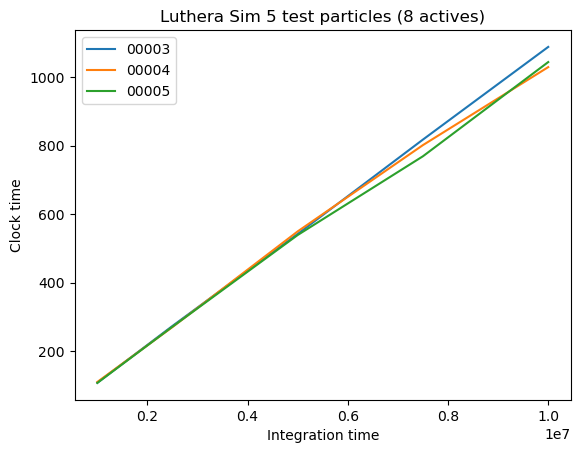

In [6]:
run_results.groupby("sim_number")["clock_time"].plot(legend=True, xlabel="Integration time", ylabel="Clock time", 
                                                     title="Luthera Sim 5 test particles (8 actives)")


In [7]:
avg_clock_time = run_results.groupby("int_length")["clock_time"].mean()

int_time = [float(int_time) for int_time in avg_clock_time.index]

lin_fit = np.polyfit(int_time, avg_clock_time,1)
reg_fun = np.poly1d(lin_fit)
print(reg_fun)

 
0.0001049 x + 9.072


In [8]:
print(reg_fun(int_time))
print(avg_clock_time)

print(f'Time to run 1.e6 {datetime.timedelta(seconds=reg_fun(1.e6))}')
print(f'Time to run 1.e7 {datetime.timedelta(seconds=reg_fun(1.e7))}')
print(f'Time to run 1.e8 {datetime.timedelta(seconds=reg_fun(1.e8))}')
print(f'Time to run 1.e9 {datetime.timedelta(seconds=reg_fun(1.e9))}')

print(f'Time to run 2.25e9 {datetime.timedelta(seconds=reg_fun(2.25e9))}')
print(f'Time to run 4.5e9 {datetime.timedelta(seconds=reg_fun(4.5e9))}')

[ 113.96121677  271.29448654  533.51660283  795.73871911 1057.96083539]
int_length
1000000.0      108.155760
2500000.0      271.621068
5000000.0      543.420321
7500000.0      795.851184
10000000.0    1053.423528
Name: clock_time, dtype: float64
Time to run 1.e6 0:01:53.961217
Time to run 1.e7 0:17:37.960835
Time to run 1.e8 2:54:57.957022
Time to run 1.e9 1 day, 5:08:17.918884
Time to run 2.25e9 2 days, 17:33:28.977025
Time to run 4.5e9 5 days, 11:06:48.881681
